# 03 — Exploratory Data Analysis
**Projeto:** iFood Customer Analytics (simulação)  
**Squad:** Customer Intelligence | **Demanda:** MKT-001 | **Área:** Marketing & CRM

## 1. Contexto e objetivos
Caracterizar renda, composição familiar, escolaridade e consumo; investigar associações e formular oportunidades para a etapa de Business Analysis. Este notebook não altera a base tratada nem estabelece causalidade. A unidade observacional é o registro deduplicado, não necessariamente um cliente único (não há chave de negócio validada). Moeda e período de renda/gastos não serão presumidos. A referência didática de imóveis inspira a sequência teoria → pergunta → cálculo → gráfico → interpretação; os dados utilizados são exclusivamente os do projeto.

**Entrada:** `data/processed/mkt_data_clean.parquet` (notebook 02). **Saídas:** tabelas CSV em `reports/` e figuras PNG em `reports/figures/`. Execute da pasta `notebooks/` ou da raiz do projeto. Dependências: pandas, numpy, matplotlib, seaborn, scipy, pyarrow. Instale no kernel se necessário: `%pip install pandas numpy matplotlib seaborn scipy pyarrow`.

### Hipóteses exploratórias
| ID | Pergunta |
|---|---|
| H01 | Renda maior está associada a gastos maiores? |
| H02 | Composição familiar está associada a gastos? |
| H03 | Escolaridade está associada à renda? |
| H04 | Estado civil está associado a gastos e filhos? |
| H05 | Consumo está concentrado em poucos registros? |
| H06 | Composição familiar está associada ao mix de produtos? |
| H07 | Extremos de renda alteram a média? |

São perguntas descritivas, não testes confirmatórios. Não inferimos intenção, causalidade ou representatividade populacional.

## 2. Ambiente e padrão visual

In [22]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd() / 'data').is_dir() else Path.cwd().parent
DATA_PATH = ROOT / 'data/processed/mkt_data_clean.parquet'
REPORTS = ROOT / 'reports'
FIGURES = REPORTS / 'figures'
RED = '#EA1D2C'
DARK = '#343434'
sns.set_theme(style='whitegrid', palette=[RED, DARK], context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def finish(fig, ax, title, xlabel, ylabel, filename):
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    fig.tight_layout()
    fig.savefig(FIGURES / (filename + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## 3. Carregamento e contrato de entrada
A validação falha deliberadamente se o artefato estiver ausente ou divergir do contrato desta versão. Não há fallback para o CSV bruto.

In [23]:
assert DATA_PATH.is_file(), 'Execute o notebook 02 para gerar o Parquet.'
df = pd.read_parquet(DATA_PATH)
assert df.shape == (2021, 31), f'Dimensões inesperadas: {df.shape}'
assert not df.isna().any().any()
assert not df.duplicated().any()
assert df['expenses'].equals(df['MntTotal'])
assert (df['kids'] == df['Kidhome'] + df['Teenhome']).all()
assert (df['MntRegularProds'] < 0).sum() == 3
FIGURES.mkdir(parents=True, exist_ok=True)
print(f'Contrato aprovado: {df.shape}')
display(df.head())

Contrato aprovado: (2021, 31)


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,Response,Age,Customer_Days,MntTotal,MntRegularProds,AcceptedCmpOverall,marital_status,education_level,kids,expenses
0,58138.0,0,0,58,635,88,546,172,88,88,...,1,63,2822,1529,1441,0,Single,Graduation,0,1529
1,46344.0,1,1,38,11,1,6,2,1,6,...,0,66,2272,21,15,0,Single,Graduation,2,21
2,71613.0,0,0,26,426,49,127,111,21,42,...,0,55,2471,734,692,0,Together,Graduation,0,734
3,26646.0,1,0,26,11,4,20,10,3,5,...,0,36,2298,48,43,0,Together,Graduation,1,48
4,58293.0,1,0,94,173,43,118,46,27,15,...,0,39,2320,407,392,0,Married,PhD,1,407


## 4. Classificação das variáveis
Tipo físico não equivale a tipo estatístico: indicadores binários são categorias codificadas; contagens são discretas. Gastos e renda são magnitudes monetárias. Evitamos duplicar `expenses`/`MntTotal` nas relações multivariadas.

In [24]:
numeric = df.select_dtypes(include='number').columns.tolist()
products = ['MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds']
flags = [x for x in numeric if set(df[x].unique()) <= {0,1}]
financial = ['Income','expenses','MntTotal','MntRegularProds'] + products
schema = pd.DataFrame({'variable': df.columns, 'dtype': df.dtypes.astype(str).values,
    'role': ['binária' if x in flags else 'monetária' if x in financial else 'numérica discreta' if x in numeric else 'categórica' for x in df]})
display(schema)

,variable,dtype,role
0,Income,float64,monetária
1,Kidhome,int64,numérica discreta
2,Teenhome,int64,numérica discreta
3,Recency,int64,numérica discreta
4,MntWines,int64,monetária
5,MntFruits,int64,monetária
6,MntMeatProducts,int64,monetária
7,MntFishProducts,int64,monetária
8,MntSweetProducts,int64,monetária
9,MntGoldProds,int64,monetária


## 5. Tendência central
A média $\bar{x}=\frac{1}{n}\sum_i x_i$ usa todas as observações; a mediana é o percentil 50 e é resistente a extremos; a moda corresponde aos valores de frequência máxima (pode haver empate). Em variáveis contínuas a moda exata pode ser pouco útil. Para indicadores binários, a média representa a proporção de registros com valor 1.

In [25]:
x = df[numeric]
summary = x.describe(percentiles=[.05,.25,.5,.75,.95]).T.rename(columns={'25%':'q1','50%':'median','75%':'q3','5%':'p05','95%':'p95'})
summary['mode'] = [', '.join(map(str, x[k].mode().tolist())) for k in numeric]
display(summary[['count','mean','median','mode','min','q1','q3','max']])

,count,mean,median,mode,min,q1,q3,max
Income,2021.0,51687.258783,51412.0,7500.0,1730.0,35416.0,68274.0,113734.0
Kidhome,2021.0,0.443345,0.0,0,0.0,0.0,1.0,2.0
Teenhome,2021.0,0.509649,0.0,0,0.0,0.0,1.0,2.0
Recency,2021.0,48.880752,49.0,56,0.0,24.0,74.0,99.0
MntWines,2021.0,306.492331,178.0,2,0.0,24.0,507.0,1493.0
MntFruits,2021.0,26.364671,8.0,0,0.0,2.0,33.0,199.0
MntMeatProducts,2021.0,166.059871,68.0,"5, 7",0.0,16.0,230.0,1725.0
MntFishProducts,2021.0,37.603662,12.0,0,0.0,3.0,50.0,259.0
MntSweetProducts,2021.0,27.268679,8.0,0,0.0,1.0,34.0,262.0
MntGoldProds,2021.0,43.921821,25.0,3,0.0,9.0,56.0,321.0


In [26]:
for k in ['Income','expenses']:
    print(f'{k}: média {x[k].mean():,.2f}; mediana {x[k].median():,.2f}; máximo {x[k].max():,.2f}')

Income: média 51,687.26; mediana 51,412.00; máximo 113,734.00
expenses: média 563.79; mediana 343.00; máximo 2,491.00


**Interpretação:** na base tratada reconstruída a partir da fonte, renda média ≈ 51.687 e mediana 51.412; gastos médios ≈ 564 e mediana 343. A diferença nos gastos recomenda reportar ambos os indicadores. Não basta comparar média e mediana para provar normalidade.

## 6. Dispersão
A variância amostral $s^2=\frac{\sum_i(x_i-\bar{x})^2}{n-1}$ mede dispersão em unidades quadráticas. O desvio padrão $s=\sqrt{s^2}$ retorna à unidade original. O coeficiente de variação $CV=100s/\bar{x}$ permite comparar magnitudes em escala de razão com média positiva; aqui o restringimos a renda e gastos totais.

In [27]:
summary['variance'] = x.var(ddof=1)
summary['range'] = x.max()-x.min()
summary['cv_pct'] = np.nan
for k in ['Income','expenses']:
    summary.loc[k,'cv_pct'] = 100*x[k].std()/x[k].mean()
display(summary.loc[['Income','expenses'],['mean','std','variance','range','cv_pct']])

,mean,std,variance,range,cv_pct
Income,51687.258783,20713.046401,4.290303e+08,112004.0,40.073796
expenses,563.789213,576.775749,3.326703e+05,2487.0,102.303438


**Interpretação:** gastos possuem dispersão relativa maior do que renda; isso sugere que médias globais escondem heterogeneidade de consumo, não que todos os segmentos sejam diferentes.

## 7. Quartis e percentis
$Q_1=P_{25}$, $Q_2=P_{50}$, $Q_3=P_{75}$; $IQR=Q_3-Q_1$. Usamos interpolação linear do Pandas. Empates podem impedir que faixas contenham exatamente 25% dos registros.

In [28]:
summary['iqr'] = summary.q3-summary.q1
display(summary.loc[['Income','expenses'],['min','p05','q1','median','q3','p95','max','iqr']])

,min,p05,q1,median,q3,p95,max,iqr
Income,1730.0,18978.0,35416.0,51412.0,68274.0,83715.0,113734.0,32858.0
expenses,4.0,18.0,55.0,343.0,964.0,1702.0,2491.0,909.0


## 8. Distribuições
Histogramas mostram frequência em intervalos; linhas de média e mediana ajudam a interpretar a forma. O número de bins altera a aparência.

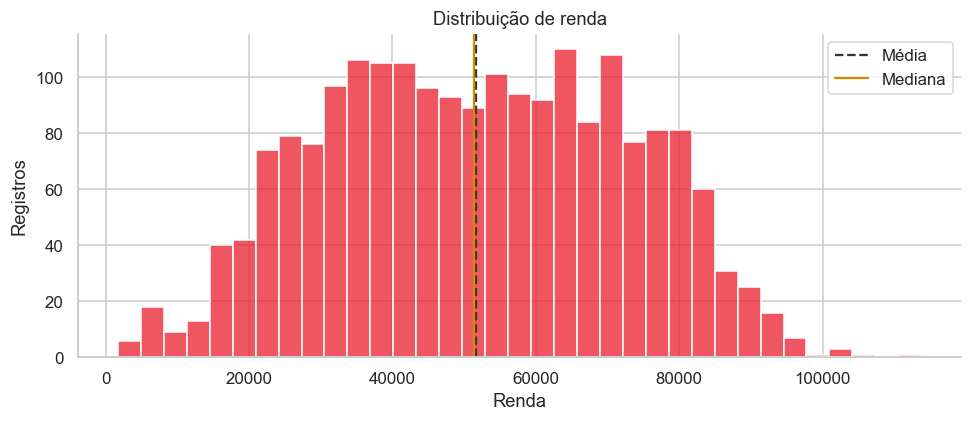

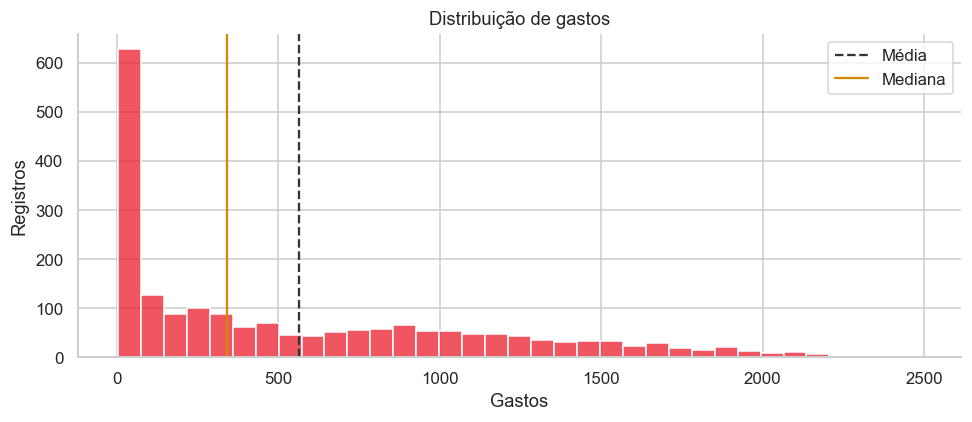

In [29]:
for k, label in [('Income','Renda'),('expenses','Gastos')]:
    fig, ax = plt.subplots(figsize=(9,4))
    sns.histplot(df[k], bins=35, color=RED, ax=ax)
    ax.axvline(df[k].mean(), color=DARK, linestyle='--', label='Média')
    ax.axvline(df[k].median(), color='#d18b00', label='Mediana')
    ax.legend()
    finish(fig, ax, f'Distribuição de {label.lower()}',label,'Registros',k.lower()+'_distribution')

**Leitura:** renda possui centro próximo de 51 mil; gastos apresentam maior diferença entre média e mediana. Examine as caudas antes de resumir um perfil por um único número.

## 9. Assimetria e curtose
Com momentos centrais $m_k=n^{-1}\sum_i(x_i-\bar{x})^k$, a assimetria de momentos é $g_1=m_3/m_2^{3/2}$ e o excesso de curtose $g_2=m_4/m_2^2-3$. Pandas aplica correções amostrais. Assimetria positiva indica cauda direita mais pronunciada; curtose descreve comportamento de caudas, não apenas altura do pico. Nenhuma dessas medidas prova normalidade.

,skewness,excess_kurtosis
Income,0.004357,-0.823566
expenses,0.919421,-0.207950


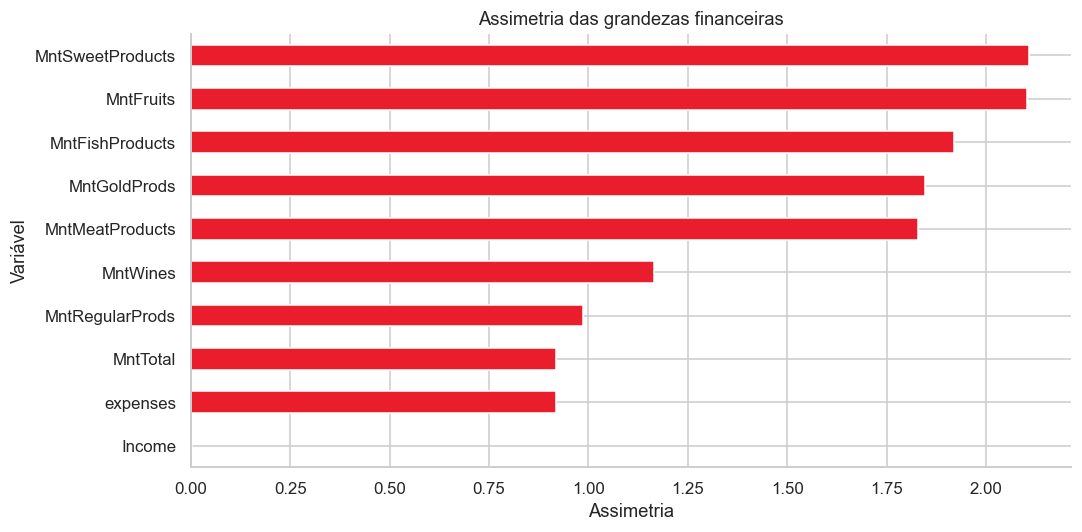

In [30]:
summary['skewness'] = x.skew()
summary['excess_kurtosis'] = x.kurt()
display(summary.loc[['Income','expenses'],['skewness','excess_kurtosis']])
fig, ax = plt.subplots(figsize=(10,5))
summary.loc[financial,'skewness'].sort_values().plot.barh(ax=ax,color=RED)
finish(fig,ax,'Assimetria das grandezas financeiras','Assimetria','Variável','financial_skewness')

## 10. Valores extremos (H07)
Regra de Tukey: $LI=Q_1-1.5IQR$, $LS=Q_3+1.5IQR$. Pontos fora dos limites são sinalizações exploratórias, não erros. Não aplicamos exclusão na base. Para indicadores discretos ou com IQR zero, a regra pode ser inadequada; restringimos a análise às duas magnitudes centrais.

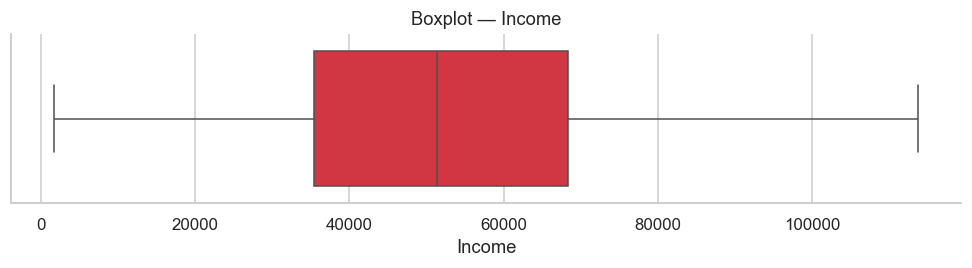

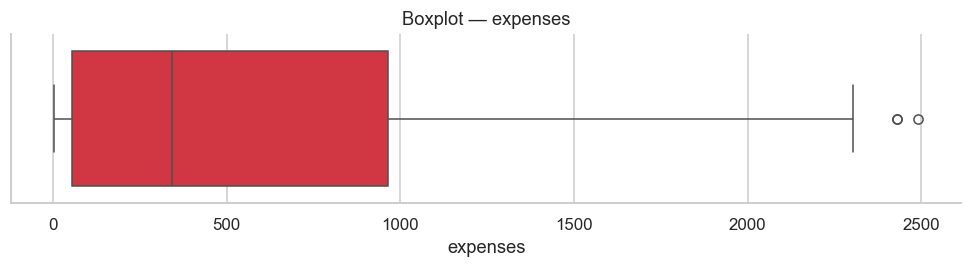

,variable,lower,upper,flagged,pct,mean_all,mean_inside
0,Income,-13871.0,117561.0,0,0.000000,51687.258783,51687.258783
1,expenses,-1308.5,2327.5,3,0.148441,563.789213,560.985629


In [31]:
outliers = []
for k in ['Income','expenses']:
    q1,q3 = df[k].quantile([.25,.75]); iqr=q3-q1
    lo,hi=q1-1.5*iqr,q3+1.5*iqr
    mask=~df[k].between(lo,hi)
    outliers.append({'variable':k,'lower':lo,'upper':hi,'flagged':int(mask.sum()),'pct':100*mask.mean(), 'mean_all':df[k].mean(),'mean_inside':df.loc[~mask,k].mean()})
    fig,ax=plt.subplots(figsize=(9,2.6)); sns.boxplot(x=df[k],color=RED,ax=ax)
    finish(fig,ax,f'Boxplot — {k}',k,'',k.lower()+'_boxplot')
outlier_table=pd.DataFrame(outliers)
display(outlier_table)

In [32]:
for row in outliers:
    print(f"{row['variable']}: {row['flagged']} sinalizados; diferença da média sem sinalizados: {row['mean_inside']-row['mean_all']:.2f}")

Income: 0 sinalizados; diferença da média sem sinalizados: 0.00
expenses: 3 sinalizados; diferença da média sem sinalizados: -2.80


A comparação sem sinalizados é apenas sensibilidade, não uma nova base. H07 deve ser avaliada pela magnitude da diferença e pela quantidade sinalizada.

## 11. Escolaridade (H03)
Frequência relativa: $p_j=n_j/n$. Compare renda por categoria com tamanho do grupo; não presuma equivalência entre rótulos educacionais de sistemas diferentes.

,n,income_median,expenses_median,expenses_mean,share_pct
education_level,,,,,
2n Cycle,183,46779.0,180.0,453.573770,9.054923
Basic,49,20194.0,40.0,61.163265,2.424542
Graduation,1015,52117.0,350.0,573.530049,50.222662
Master,335,51124.0,339.0,579.229851,16.575952
PhD,439,54959.0,446.0,631.530752,21.721920


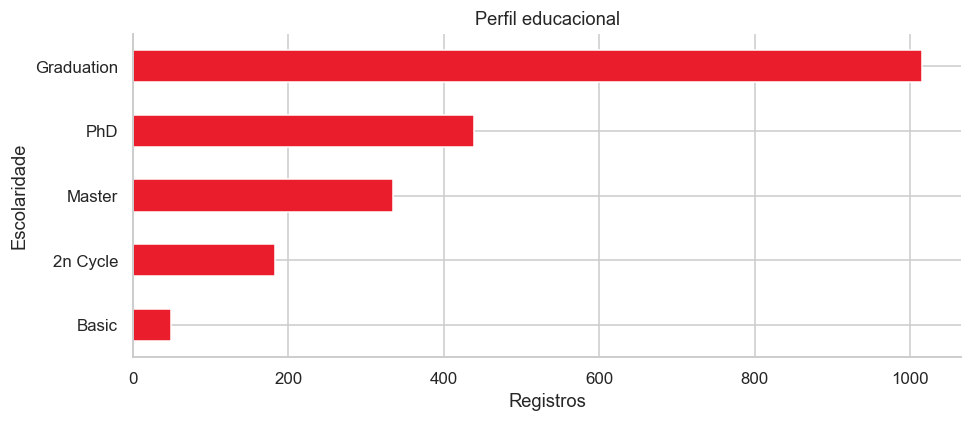

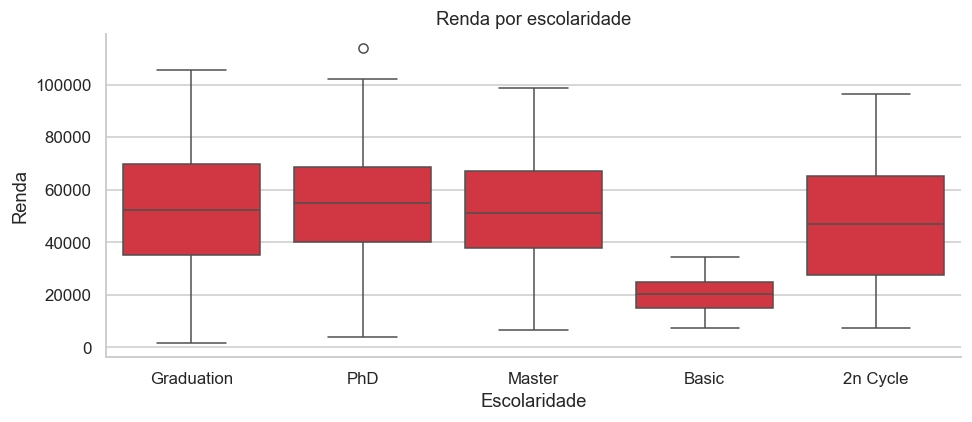

In [33]:
def profile(col):
    t=df.groupby(col,observed=True).agg(n=('Income','size'),income_median=('Income','median'),expenses_median=('expenses','median'),expenses_mean=('expenses','mean'))
    t['share_pct']=100*t.n/len(df)
    return t
education=profile('education_level'); display(education)
fig,ax=plt.subplots(figsize=(9,4)); education.n.sort_values().plot.barh(ax=ax,color=RED)
finish(fig,ax,'Perfil educacional','Registros','Escolaridade','education_profile')
fig,ax=plt.subplots(figsize=(9,4)); sns.boxplot(data=df,x='education_level',y='Income',color=RED,ax=ax)
finish(fig,ax,'Renda por escolaridade','Escolaridade','Renda','income_by_education')

Graduation é a categoria mais frequente (1.015 registros). Basic apresenta mediana de renda de 20.194, inferior à de PhD (54.959), porém tem somente 49 registros. Associação descritiva não implica efeito da escolaridade.

## 12. Estado civil (H04)

,n,income_median,expenses_median,expenses_mean,share_pct
marital_status,,,,,
Divorced,214,52683.0,349.0,565.228972,10.588817
Married,785,51948.0,345.0,549.611465,38.842157
Single,443,48904.0,303.0,567.900677,21.919842
Together,509,51369.0,313.0,563.628684,25.185552
Widow,70,57032.0,598.5,693.528571,3.463632


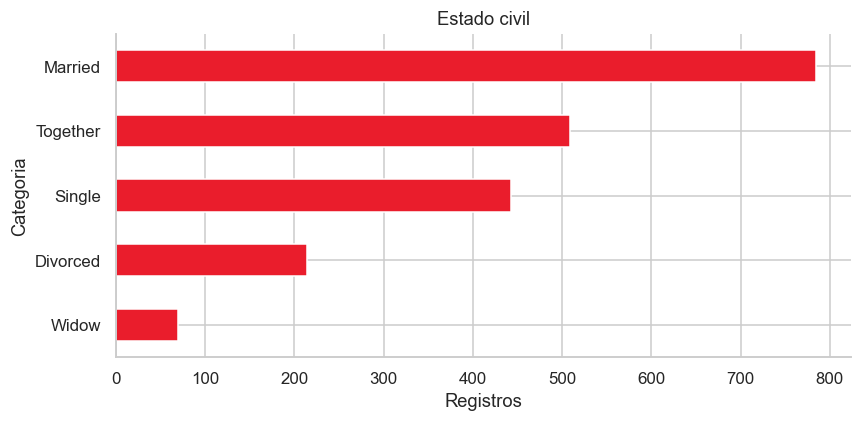

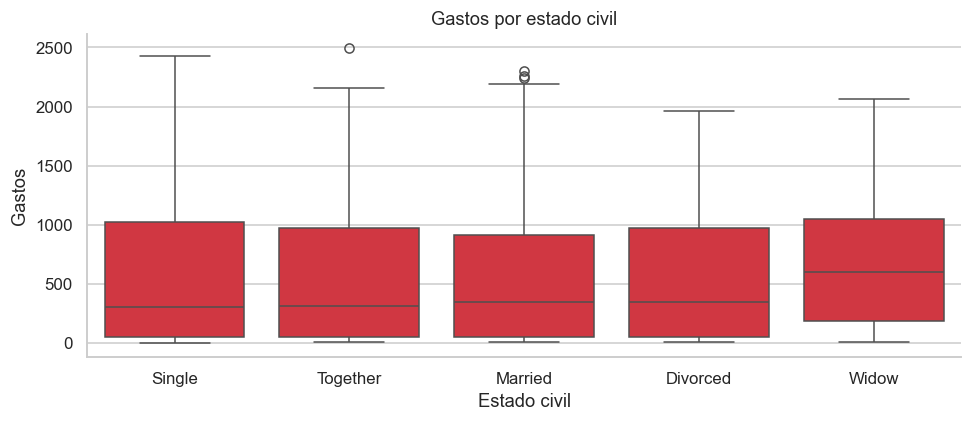

In [34]:
marital=profile('marital_status'); display(marital)
fig,ax=plt.subplots(figsize=(8,4)); marital.n.sort_values().plot.barh(ax=ax,color=RED)
finish(fig,ax,'Estado civil','Registros','Categoria','marital_status_profile')
fig,ax=plt.subplots(figsize=(9,4)); sns.boxplot(data=df,x='marital_status',y='expenses',color=RED,ax=ax)
finish(fig,ax,'Gastos por estado civil','Estado civil','Gastos','expenses_by_marital')

Married é o maior grupo (785 registros). Widow tem mediana de gastos de 598,5, mas somente 70 registros. O tamanho do grupo deve acompanhar toda comparação.

## 13. Composição familiar (H02 e H04)
Compare proporções condicionais por estado civil, não apenas contagens absolutas.

,n,income_median,expenses_median,expenses_mean,share_pct
kids,,,,,
0,567,72298.0,1114.0,1056.282187,28.055418
1,1027,47320.0,265.0,432.732230,50.816428
2,382,44116.5,84.0,223.267016,18.901534
3,45,45072.0,62.0,240.044444,2.226620


kids,0,1,2,3
marital_status,,,,
Divorced,53,108,48,5
Married,202,412,158,13
Single,154,210,66,13
Together,133,266,96,14
Widow,25,31,14,0


kids,0,1,2,3
marital_status,,,,
Divorced,24.77,50.47,22.43,2.34
Married,25.73,52.48,20.13,1.66
Single,34.76,47.40,14.90,2.93
Together,26.13,52.26,18.86,2.75
Widow,35.71,44.29,20.00,0.00


,size,mean,median
marital_status,,,
Divorced,214,1.023364,1.0
Married,785,0.977070,1.0
Single,443,0.860045,1.0
Together,509,0.982318,1.0
Widow,70,0.842857,1.0


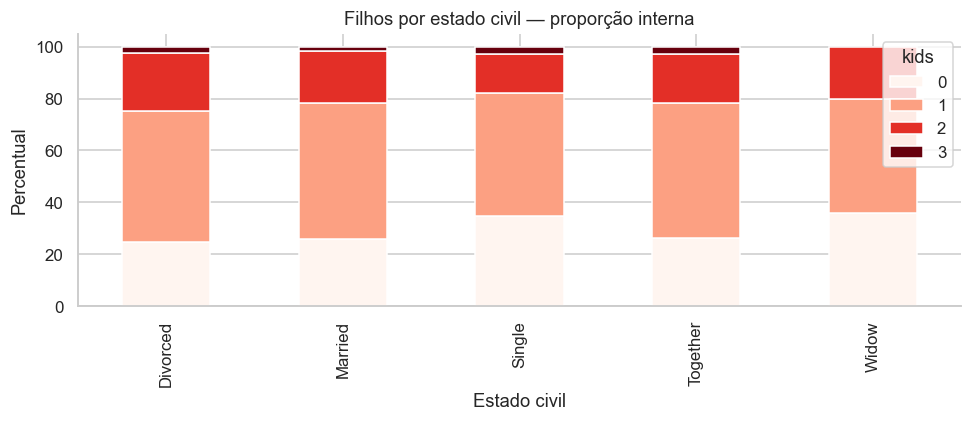

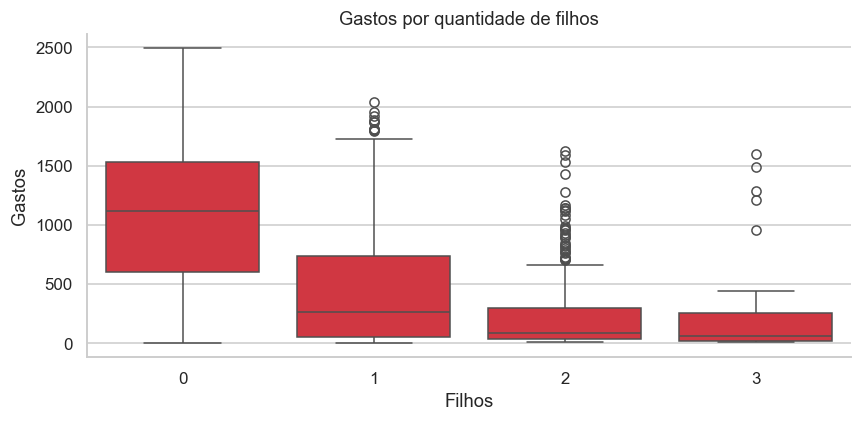

In [35]:
family=profile('kids'); display(family)
family_cross=pd.crosstab(df.marital_status,df.kids)
family_pct=pd.crosstab(df.marital_status,df.kids,normalize='index')*100
display(family_cross); display(family_pct.round(2))
display(df.groupby('marital_status').kids.agg(['size','mean','median']))
fig,ax=plt.subplots(figsize=(9,4)); family_pct.plot.bar(stacked=True,ax=ax,colormap='Reds')
finish(fig,ax,'Filhos por estado civil — proporção interna','Estado civil','Percentual','kids_by_marital')
fig,ax=plt.subplots(figsize=(8,4)); sns.boxplot(data=df,x='kids',y='expenses',color=RED,ax=ax)
finish(fig,ax,'Gastos por quantidade de filhos','Filhos','Gastos','expenses_by_kids')

A mediana de gastos cai de 1.114 (sem filhos) para 265 (um), 84 (dois) e 62 (três). O último grupo tem 45 registros. Para verificar se casados têm mais filhos, compare a média, mediana e proporções internas exibidas acima; não use apenas a contagem de casados.

## 14. Consumo e concentração (H05 e H06)
Somamos categorias apenas entre as seis colunas de produtos; não somamos `expenses` com `MntTotal`. O mix representa participação no total destas seis categorias, não necessariamente no KPI `expenses`.

,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
kids,,,,,,
0,44.40,4.74,33.39,6.89,4.85,5.73
1,56.66,4.09,20.74,5.66,4.28,8.57
2,57.48,3.19,20.88,4.69,3.39,10.37
3,62.25,2.52,23.81,2.10,2.15,7.18


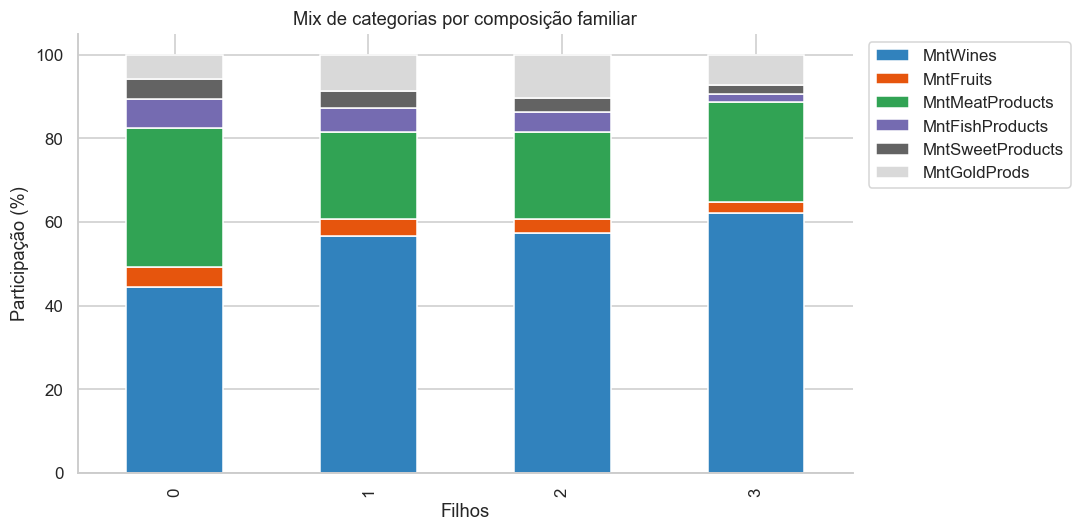

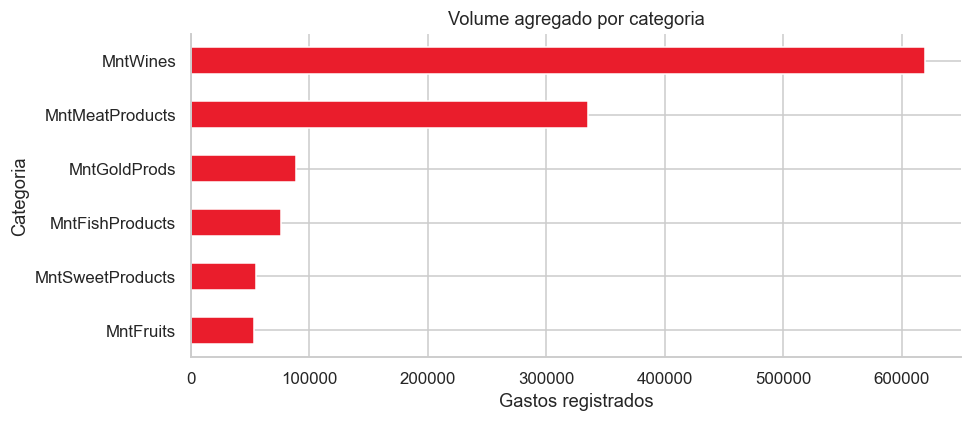

In [36]:
mix=df.groupby('kids')[products].sum()
mix_pct=mix.div(mix.sum(axis=1),axis=0)*100
display(mix_pct.round(2))
fig,ax=plt.subplots(figsize=(10,5)); mix_pct.plot.bar(stacked=True,ax=ax,colormap='tab20c')
ax.legend(bbox_to_anchor=(1.01,1),loc='upper left')
finish(fig,ax,'Mix de categorias por composição familiar','Filhos','Participação (%)','product_mix_by_kids')
fig,ax=plt.subplots(figsize=(9,4)); df[products].sum().sort_values().plot.barh(ax=ax,color=RED)
finish(fig,ax,'Volume agregado por categoria','Gastos registrados','Categoria','product_totals')

Top 405 registros: 53.67% dos gastos


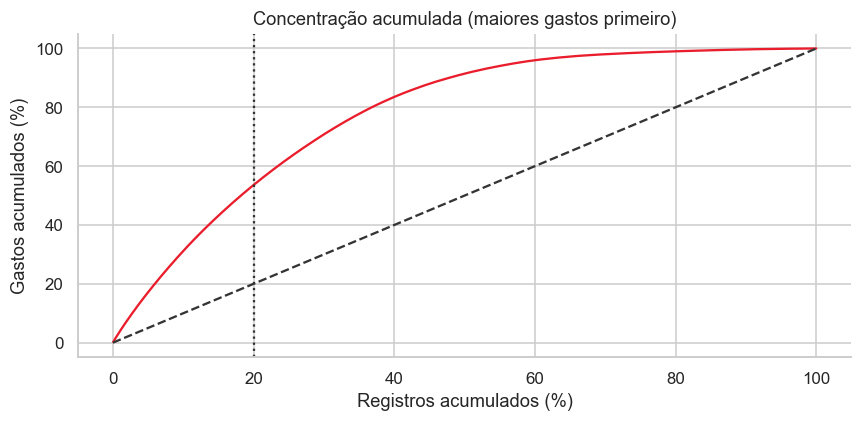

In [37]:
ordered=df.expenses.sort_values(ascending=False).to_numpy()
n_top=int(np.ceil(.2*len(ordered)))
top_share=100*ordered[:n_top].sum()/ordered.sum()
print(f'Top {n_top} registros: {top_share:.2f}% dos gastos')
fig,ax=plt.subplots(figsize=(8,4)); ax.plot(np.arange(1,len(ordered)+1)/len(ordered)*100,np.cumsum(ordered)/ordered.sum()*100,color=RED)
ax.plot([0,100],[0,100],'--',color=DARK); ax.axvline(20,ls=':',color=DARK)
finish(fig,ax,'Concentração acumulada (maiores gastos primeiro)','Registros acumulados (%)','Gastos acumulados (%)','spending_concentration')

Use a participação observada do top 20% para avaliar concentração; não suponha a regra 80/20. Diferenças no mix podem gerar hipóteses de campanhas, mas não demonstram preferência individual ou resposta incremental.

## 15. Correlações (H01)
Pearson mede associação linear:
$$r=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i(x_i-\bar x)^2\sum_i(y_i-\bar y)^2}}$$
Spearman é Pearson aplicado aos postos, com tratamento de empates; mede associação monotônica. Ambos variam de -1 a 1. Correlação não implica causalidade.

Pearson: 0.8192 | Spearman: 0.8678


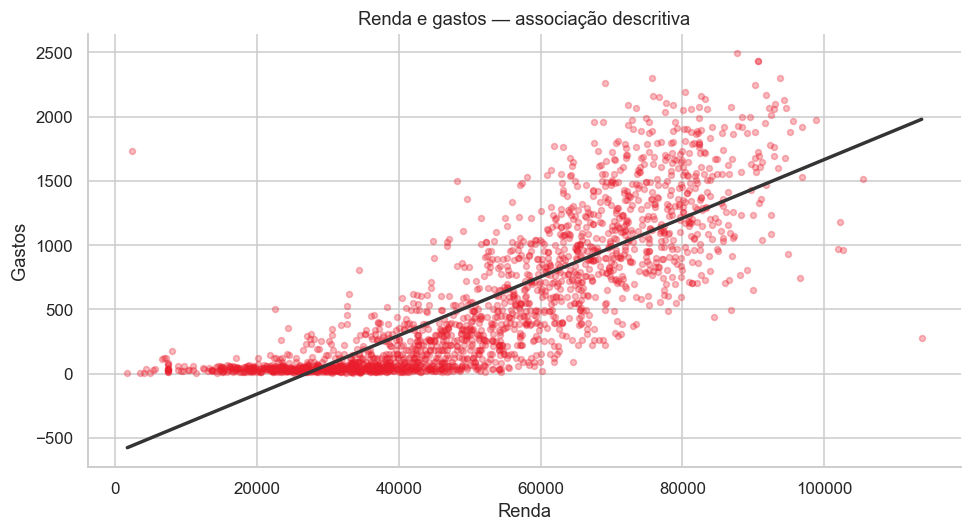

In [38]:
pair=df[['Income','expenses']]
r=pair.corr().iloc[0,1]; rho=pair.corr(method='spearman').iloc[0,1]
print(f'Pearson: {r:.4f} | Spearman: {rho:.4f}')
fig,ax=plt.subplots(figsize=(9,5)); sns.regplot(data=df,x='Income',y='expenses',ci=None,scatter_kws={'alpha':.3,'s':15},line_kws={'color':DARK},color=RED,ax=ax)
finish(fig,ax,'Renda e gastos — associação descritiva','Renda','Gastos','income_vs_expenses')

Pearson ≈ 0,819 e Spearman ≈ 0,868 na base reconstruída: associação positiva forte na amostra. A diferença sugere investigar não linearidade; não corresponde a efeito causal de renda sobre gastos.

## 16. Matriz de correlação
Selecionamos variáveis centrais e evitamos redundâncias determinísticas (MntTotal, componentes de kids). Não interpretamos correlações parte-todo como descobertas independentes.

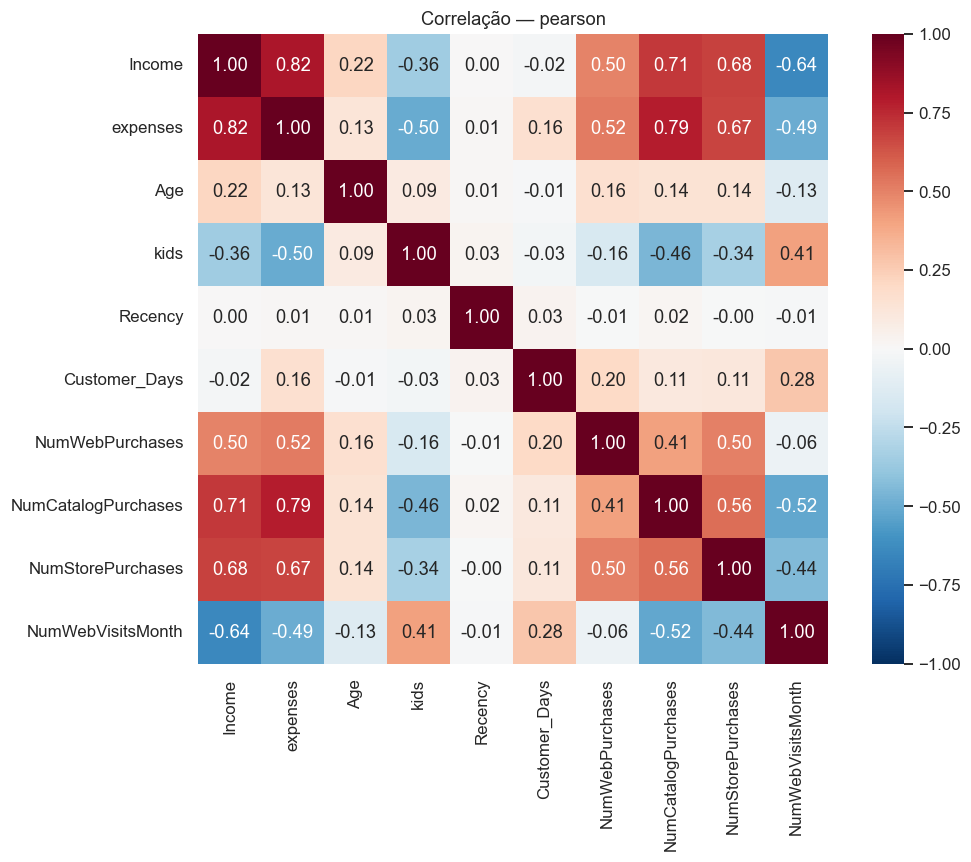

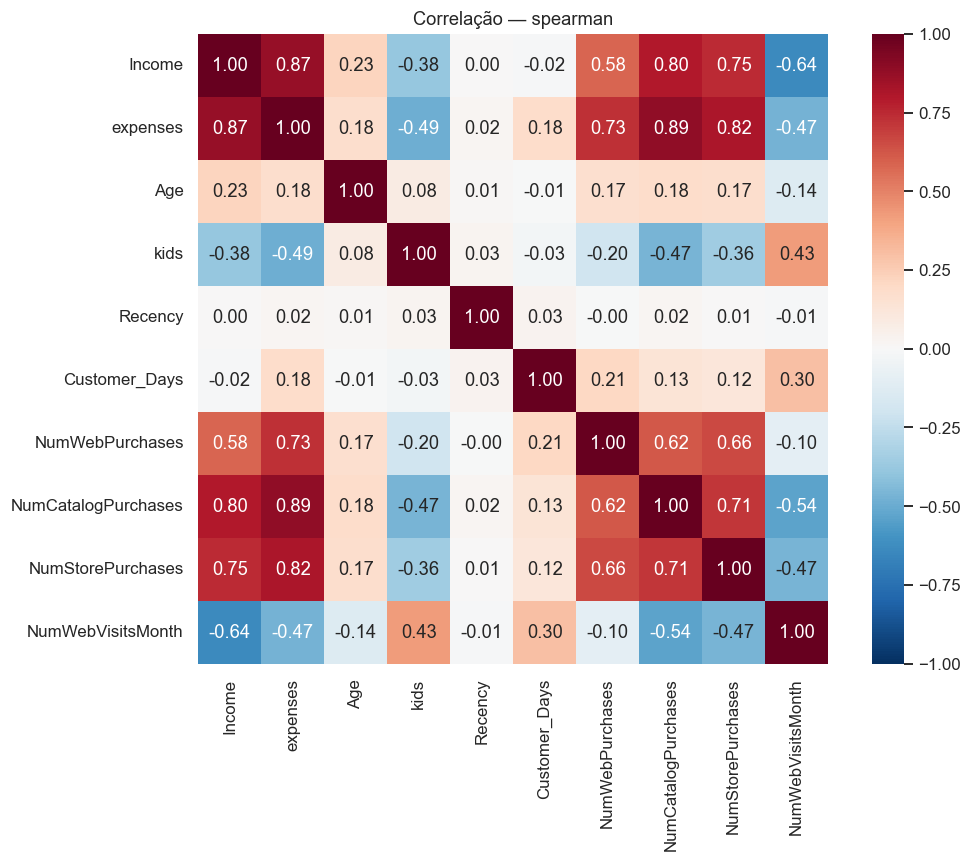

In [39]:
features=['Income','expenses','Age','kids','Recency','Customer_Days','NumWebPurchases','NumCatalogPurchases','NumStorePurchases','NumWebVisitsMonth']
pearson=df[features].corr(); spearman=df[features].corr(method='spearman')
for name,matrix in [('pearson',pearson),('spearman',spearman)]:
    fig,ax=plt.subplots(figsize=(10,8)); sns.heatmap(matrix,annot=True,fmt='.2f',vmin=-1,vmax=1,center=0,cmap='RdBu_r',square=True,ax=ax)
    finish(fig,ax,'Correlação — '+name,'','','correlation_'+name)

## 17. Investigação de hipóteses e estratificação
Para investigar possível confundimento pela renda, comparamos gastos por filhos dentro de quartis de renda. Esta estratificação não controla todos os fatores nem constitui teste causal.

,income_band,kids,n,median,mean
0,Q1,0,87,50.0,106.678161
1,Q1,1,314,40.5,60.863057
2,Q1,2,94,38.5,48.840426
3,Q1,3,11,27.0,38.090909
4,Q2,0,43,276.0,404.418605
5,Q2,1,263,182.0,227.935361
6,Q2,2,180,66.0,131.716667
7,Q2,3,19,53.0,90.210526
8,Q3,0,87,1006.0,983.609195
9,Q3,1,317,699.0,691.365931


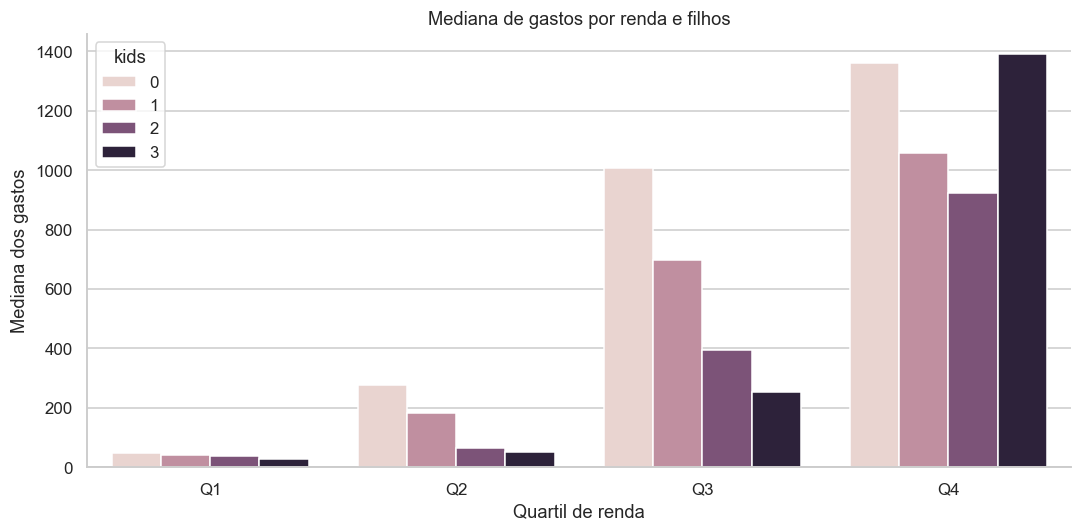

In [40]:
analysis=df.assign(income_band=pd.qcut(df.Income,4,labels=['Q1','Q2','Q3','Q4']))
stratified=analysis.groupby(['income_band','kids'],observed=True).expenses.agg(n='size',median='median',mean='mean').reset_index()
display(stratified)
fig,ax=plt.subplots(figsize=(10,5)); sns.barplot(data=stratified,x='income_band',y='median',hue='kids',ax=ax)
finish(fig,ax,'Mediana de gastos por renda e filhos','Quartil de renda','Mediana dos gastos','expenses_stratified')

Grupos pequenos exigem cautela. Diferenças dentro das faixas podem persistir ou diminuir; use a tabela para verificar o tamanho de cada célula. Não houve testes de significância nem correção por comparações múltiplas.

## 18. Sensibilidade aos negativos
Os três registros preservados no notebook 02 não são removidos da base. Comparamos indicadores com e sem esses registros apenas em uma visão temporária.

In [41]:
valid=df.MntRegularProds>=0
sensitivity=pd.DataFrame({'all':df[['Income','expenses','MntRegularProds']].mean(),'without_negative_rows':df.loc[valid,['Income','expenses','MntRegularProds']].mean()})
sensitivity['difference']=sensitivity.without_negative_rows-sensitivity['all']
display(sensitivity)

,all,without_negative_rows,difference
Income,51687.258783,51755.112983,67.854200
expenses,563.789213,564.491576,0.702363
MntRegularProds,519.867392,520.937562,1.070170


## 19. Exportação e rastreabilidade
As tabelas são artefatos derivados; o Parquet permanece intacto.

In [42]:
profiles=pd.concat([education.reset_index().rename(columns={'education_level':'category'}).assign(dimension='education_level'),marital.reset_index().rename(columns={'marital_status':'category'}).assign(dimension='marital_status'),family.reset_index().rename(columns={'kids':'category'}).assign(dimension='kids')],ignore_index=True)
exports={'descriptive_statistics':summary.rename_axis('variable').reset_index(),'correlation_matrix':pearson,'correlation_spearman':spearman,'outlier_analysis':outlier_table,'customer_profile':profiles,'family_by_marital_pct':family_pct,'product_mix':mix_pct,'stratified_expenses':stratified,'sensitivity_analysis':sensitivity}
for name,table in exports.items():
    table.to_csv(REPORTS/(name+'.csv'),index=name in {'correlation_matrix','correlation_spearman','family_by_marital_pct','product_mix','sensitivity_analysis'})
print(f'{len(exports)} tabelas exportadas; {len(list(FIGURES.glob("*.png")))} PNGs presentes.')

9 tabelas exportadas; 18 PNGs presentes.


## 20. Conclusões e parecer técnico
### Síntese executiva
A análise caracteriza 2.021 registros com 31 variáveis. Na reconstrução da base fornecida, renda e consumo apresentam associação positiva expressiva; gastos são heterogêneos e a composição familiar diferencia medianas de consumo. O máximo de renda é 113.734, sem unidade monetária confirmada. Os indicadores devem ser confirmados pela execução no Parquet local.

| Hipótese | Evidência / encaminhamento |
|---|---|
| H01 | Associação positiva na amostra; investigar segmentação. |
| H02 | Medianas distintas por filhos; estratificar por renda. |
| H03 | Diferenças entre categorias educacionais; considerar tamanhos. |
| H04 | Comparar proporções condicionais de filhos e distribuição de gastos. |
| H05 | Quantificar concentração pelo top 20%, sem impor Pareto. |
| H06 | Examinar mix por grupo; testar campanhas separadamente. |
| H07 | Comparar média com e sem extremos sinalizados, sem alterar fonte. |

### Registro de riscos
| Risco | Impacto | Mitigação |
|---|---|---|
| Granularidade sem chave | Registros não equivalem necessariamente a clientes únicos | Validar com proprietário da fonte |
| Valores negativos | Distorção potencial de indicadores | Sensibilidade e validação de negócio |
| Variáveis redundantes | Dupla contagem | Usar expenses como KPI único |
| Categorias pequenas | Estimativas instáveis | Reportar n e evitar generalização |
| Moeda/período desconhecidos | Interpretação monetária indevida | Confirmar dicionário |
| Associação não causal | Decisões de marketing indevidas | Experimentos controlados posteriormente |

### Critérios de aceite
Contrato de entrada aprovado; estatísticas de todas as colunas numéricas; perfil de renda, escolaridade, estado civil e filhos; correlações e sensibilidade; exportação de tabelas e figuras. Conferir execução integral antes de marcar como concluído.

### Próxima etapa — 04 Business Analysis
Priorizar oportunidades de CRM por segmentos, definir KPI e desenhar hipóteses de campanha com métricas de sucesso, grupo de controle e limitações. Não prometer incremento de receita a partir desta EDA. A base tratada permanece inalterada.